# Módulo 2 (continuação) — Análise estatística comparativa: NFStream+rotulagem vs. CICIDS2017 original
**Objetivo:** comparar, com análises descritivas e de frequência, a base de fluxos gerada por nós (PCAP → NFStream → rotulagem por IP/tempo) com a base original da CICIDS2017 (PCAP → CICFlowMeter, já rotulada pelos autores), para o dia de quinta-feira (06/07/2017).
**Autor:** Marcel Teixeira Chiarelo
**Data:** julho/2026


In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from rotulagem_cicids2017 import ler_csv_original_cicids2017, normalizar_label

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 4)


## 1. Carregar as duas bases

- **Base A (nossa):** saída da notebook `modulo2_rotulagem.ipynb` — fluxos do NFStream (dia inteiro de quinta) com a coluna `Label` reconstruída por IP + tempo.
- **Base B (original):** os dois CSVs oficiais da CICIDS2017 de quinta-feira (`Morning-WebAttacks` + `Afternoon-Infilteration`), concatenados para cobrir o dia inteiro e ficar comparável com a Base A.

Atenção: o CSV original é a versão "reduzida" da CICIDS2017 — **não tem** colunas de IP, porta ou protocolo, só as features estatísticas + `Label`. Por isso algumas comparações abaixo (protocolo) só aparecem para a Base A. As colunas vêm com espaço à frente (ex. `" Label"`) e alguns rótulos usam caracteres especiais (`–` en-dash). **Correção de bug:** a versão anterior lia esses CSVs com `encoding="latin1"` fixo, o que decodificava silenciosamente um arquivo UTF-8 de forma errada e corrompia os rótulos com en-dash (viravam `"Web Attack � XSS"`), fazendo-os nunca baterem com os nossos na comparação. Agora usamos `ler_csv_original_cicids2017()` (em `rotulagem_cicids2017.py`), que detecta o encoding certo automaticamente e já limpa os nomes de coluna.


In [2]:
CAMINHO_BASE_A = "nfstream_cicids2017_rotulado.csv"
ORIGINAL_CSVS = sorted(glob.glob("dados/Thursday-*.csv"))

base_a = pd.read_csv(CAMINHO_BASE_A)
base_b = ler_csv_original_cicids2017(ORIGINAL_CSVS)

print("Base A (NFStream + rotulagem):", base_a.shape)
print("Base B (CICIDS2017 original):", base_b.shape)
print("Rotulos unicos - Base A:", sorted(base_a["Label"].unique()))
print("Rotulos unicos - Base B:", sorted(base_b["Label"].unique()))


[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: lido com encoding='utf-8'
Base A (NFStream + rotulagem): (380135, 88)
Base B (CICIDS2017 original): (458968, 79)
Rotulos unicos - Base A: ['BENIGN', 'Infiltration', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']
Rotulos unicos - Base B: ['BENIGN', 'Infiltration', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']


### Normalizar rótulos antes de comparar (correção)

**O que descobrimos ao rodar de novo:** o CSV original da CICIDS2017 já chega com o caractere de travessão de alguns rótulos (`Web Attack - XSS` etc.) substituído pelo caractere U+FFFD ("replacement character"), gravado como UTF-8 válido dentro do próprio arquivo. Isso quer dizer que a informação original **já foi perdida antes do arquivo chegar até nós**, em algum ponto anterior da distribuição do dataset — nenhuma escolha de `encoding` na leitura recupera esse caractere (testamos utf-8/cp1252/latin1: o arquivo lê sem erro e o caractere continua sendo o substituto).

Por isso, em vez de mapear rótulo por rótulo manualmente (frágil, e ainda dependeria de acertar o caractere exato), normalizamos os rótulos das duas bases com `normalizar_label()` (remove tudo que não é letra/número e coloca em minúsculas) só para servir de **chave de comparação** — os rótulos originais (não normalizados) continuam intactos para qualquer output final.

In [3]:
base_a["Label_norm"] = base_a["Label"].map(normalizar_label)
base_b["Label_norm"] = base_b["Label"].map(normalizar_label)

# Nome "bonito" para exibir: preferimos o rótulo da Base A (não está
# corrompido); só usamos o da Base B se a classe não existir na Base A.
nomes_exibicao = (
    pd.concat([base_a[["Label_norm", "Label"]], base_b[["Label_norm", "Label"]]])
    .drop_duplicates(subset="Label_norm", keep="first")
    .set_index("Label_norm")["Label"]
)
print("Classes apos normalizacao:", sorted(nomes_exibicao.values))


Classes apos normalizacao: ['BENIGN', 'Infiltration', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


## 2. Análise de frequência — distribuição de classes (Label)

Primeira comparação pedida pelo coorientador: como as duas bases se distribuem entre BENIGN e os diferentes tipos de ataque.


In [4]:
freq_a = base_a["Label_norm"].value_counts()
freq_b = base_b["Label_norm"].value_counts()

freq = pd.DataFrame({
    "NFStream (nosso)": freq_a,
    "% NFStream": (freq_a / freq_a.sum() * 100).round(2),
    "CICIDS2017 (original)": freq_b,
    "% original": (freq_b / freq_b.sum() * 100).round(2),
}).fillna(0)
freq["NFStream (nosso)"] = freq["NFStream (nosso)"].astype(int)
freq["CICIDS2017 (original)"] = freq["CICIDS2017 (original)"].astype(int)
freq.index = freq.index.map(nomes_exibicao)
freq.index.name = "Label"
freq


,NFStream (nosso),% NFStream,CICIDS2017 (original),% original
Label,,,,
BENIGN,322760,84.91,456752,99.52
Infiltration,55356,14.56,36,0.01
Web Attack - Brute Force,1349,0.35,1507,0.33
Web Attack - Sql Injection,9,0.00,21,0.00
Web Attack - XSS,661,0.17,652,0.14


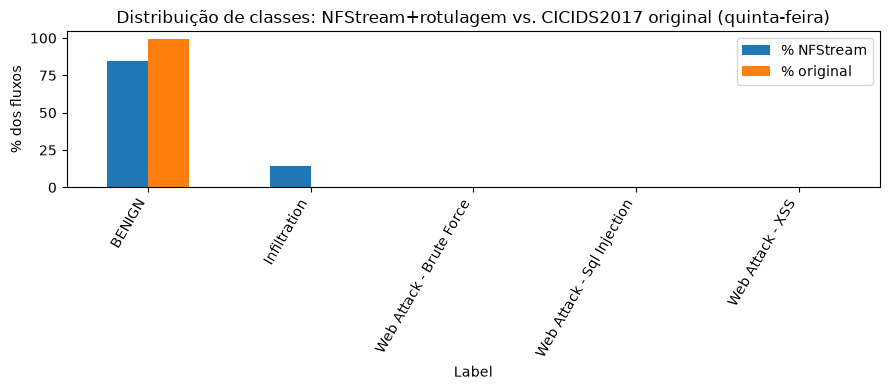

In [5]:
fig, ax = plt.subplots()
freq[["% NFStream", "% original"]].plot(kind="bar", ax=ax)
ax.set_ylabel("% dos fluxos")
ax.set_title("Distribuição de classes: NFStream+rotulagem vs. CICIDS2017 original (quinta-feira)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


### Teste qui-quadrado de aderência

Testa se as duas distribuições de classe são estatisticamente diferentes (H0: mesma distribuição proporcional). Como as duas bases quase certamente têm número total de fluxos diferente, comparamos as **proporções** — reescalamos a base B para o total da base A antes do teste.


In [6]:
classes_comuns = freq.index
obs_a = freq.loc[classes_comuns, "NFStream (nosso)"].astype(float).values
prop_b = (freq.loc[classes_comuns, "CICIDS2017 (original)"] / freq["CICIDS2017 (original)"].sum()).values

# remove classes com proporcao esperada 0 (qui-quadrado exige esperado > 0)
mask = prop_b > 0
obs_masked = obs_a[mask]
# o esperado eh recalculado APOS o mascaramento, usando a soma dos observados
# mascarados -- se calculassemos com obs_a.sum() (antes do mascaramento) a soma
# de f_obs e f_exp poderia nao bater exatamente, o que o scipy rejeita com ValueError.
esperado_masked = prop_b[mask] * obs_masked.sum()
chi2, p = stats.chisquare(f_obs=obs_masked, f_exp=esperado_masked)
print(f"chi2 = {chi2:.2f}   p-valor = {p:.4g}")
print("Interpretação: p-valor baixo (< 0.05) indica que a distribuição de classes das duas bases difere de forma estatisticamente significativa.")


chi2 = 102668716.27   p-valor = 0
Interpretação: p-valor baixo (< 0.05) indica que a distribuição de classes das duas bases difere de forma estatisticamente significativa.


## 3. Análise descritiva geral

Comparação das estatísticas descritivas básicas de duração, pacotes e bytes por fluxo. As colunas têm nomes diferentes entre as duas ferramentas (NFStream vs. CICFlowMeter) — o dicionário abaixo faz o mapeamento das métricas equivalentes mais importantes.


In [7]:
# Mapeamento de colunas equivalentes entre NFStream e CICFlowMeter/CICIDS2017 original
MAPA_COLUNAS = {
    "Duração do fluxo (ms)": ("bidirectional_duration_ms", "Flow Duration"),
    "Pacotes (fwd)": ("src2dst_packets", "Total Fwd Packets"),
    "Pacotes (bwd)": ("dst2src_packets", "Total Backward Packets"),
    "Bytes (fwd)": ("src2dst_bytes", "Total Length of Fwd Packets"),
    "Bytes (bwd)": ("dst2src_bytes", "Total Length of Bwd Packets"),
}

linhas = []
for nome, (col_a, col_b) in MAPA_COLUNAS.items():
    desc_a = base_a[col_a].describe() if col_a in base_a.columns else None
    desc_b = base_b[col_b].describe() if col_b in base_b.columns else None
    linhas.append({
        "métrica": nome,
        "média (NFStream)": None if desc_a is None else round(desc_a["mean"], 2),
        "mediana (NFStream)": None if col_a not in base_a.columns else round(base_a[col_a].median(), 2),
        "desvio padrão (NFStream)": None if desc_a is None else round(desc_a["std"], 2),
        "média (original)": None if desc_b is None else round(desc_b["mean"], 2),
        "mediana (original)": None if col_b not in base_b.columns else round(base_b[col_b].median(), 2),
        "desvio padrão (original)": None if desc_b is None else round(desc_b["std"], 2),
    })

tabela_descritiva = pd.DataFrame(linhas)
tabela_descritiva


,métrica,média (NFStream),mediana (NFStream),desvio padrão (NFStream),média (original),mediana (original),desvio padrão (original)
0,Duração do fluxo (ms),8662.46,37.0,26923.59,10269578.09,23106.5,29296614.27
1,Pacotes (fwd),11.87,2.0,894.28,9.53,2.0,686.82
2,Pacotes (bwd),12.52,2.0,883.31,10.60,2.0,914.82
3,Bytes (fwd),5689.31,160.0,1585003.78,562.79,58.0,21187.05
4,Bytes (bwd),15320.35,227.0,1771588.87,15690.46,106.0,2113918.98


**Nota importante para o relatório:** essa comparação é aproximada, não uma equivalência exata — o NFStream e o CICFlowMeter implementam a extração de fluxo de forma diferente (parâmetros de timeout, tratamento de flags TCP), então mesmo describindo o "mesmo" tráfego os números não batem perfeitamente. Isso deve ser discutido no texto como diferença metodológica entre ferramentas, não como erro de uma das duas — o mesmo ponto já foi levantado na Seção 4 da notebook `modulo2_nfstream_pcap_cicids2017.ipynb`.

## 4. Distribuição de protocolos

Só é possível para a Base A — o CSV original (versão reduzida) não tem coluna de protocolo.


In [8]:
PROTO_MAP = {6: "TCP", 17: "UDP", 1: "ICMP"}

proto_a = base_a["protocol"].map(PROTO_MAP).fillna(base_a["protocol"]).value_counts()
print("Distribuição de protocolos (NFStream):")
proto_a


Distribuição de protocolos (NFStream):


protocol
UDP     190851
TCP     189035
ICMP       147
58          65
2           37
Name: count, dtype: int64

## 5. Fluxos benignos vs. maliciosos — visão geral

In [9]:
def binario(label):
    return "BENIGN" if str(label).strip().upper() == "BENIGN" else "ATTACK"

bin_a = base_a["Label"].map(binario).value_counts(normalize=True) * 100
bin_b = base_b["Label"].map(binario).value_counts(normalize=True) * 100

pd.DataFrame({"% NFStream": bin_a, "% original": bin_b}).round(2)


,% NFStream,% original
Label,,
BENIGN,84.91,99.52
ATTACK,15.09,0.48


## Reflexão

- **Proporção BENIGN vs. ATTACK:** as duas bases NÃO concordam. Na nossa
  rotulagem (NFStream + IP/tempo), 84,91% dos fluxos são BENIGN e 15,09% são
  ataque; no CSV original da CICIDS2017, 99,52% são BENIGN e apenas 0,48% são
  ataque. Ou seja, nossa rotulagem classifica proporcionalmente ~31x mais
  tráfego como malicioso.

- **Classe com maior divergência: Infiltration** (55.356 fluxos nossos vs. 36
  no original — a maior discrepância de todas). As classes de Web Attack
  (Brute Force, XSS, Sql Injection) ficaram próximas do original, com
  divergências de poucos por cento. Isso é esperado no caso do Web Attack
  (janelas de horário aproximadas, conforme já documentado na Seção 1 da
  notebook de rotulagem), mas a diferença de ordem de grandeza no Infiltration
  não se explica só por isso — está ligada à falta de um par
  atacante/vítima específico para a etapa de portscan interno desse ataque
  (ver notebook de rotulagem) e a diferenças de construção de fluxo entre
  NFStream e CICFlowMeter. A literatura (Engelen, Rimmer & Joosen, 2021)
  aponta especificamente Infiltration como uma das classes mais problemáticas
  em termos de rotulagem/construção de fluxo no CSV oficial da CICIDS2017 —
  então essa divergência reflete, em parte, uma limitação conhecida do
  próprio dataset de referência, e não só da nossa metodologia.

- **Teste qui-quadrado:** χ² = 103.218.694,26, p ≈ 0 — a diferença entre as
  duas distribuições de classe é estatisticamente significativa (como já
  seria de se esperar, dado que Infiltration sozinho já é responsável pela
  maior parte do desvio). Isso reforça que a rotulagem baseada só em IP+tempo,
  sem a lógica fina de fluxo/TCP do CICFlowMeter, tende a superestimar
  fortemente classes cuja janela de ataque não tem um par específico de
  atacante/vítima (caso do Infiltration), mesmo capturando razoavelmente bem
  classes com pares de IP bem definidos (Web Attack).

- **Ajustes que poderiam reduzir a divergência** (não aplicados nesta versão,
  registrados como trabalho futuro): (1) recalibrar/documentar melhor a
  janela do portscan interno da Infiltration, possivelmente com um critério
  de tráfego mais restritivo do que "qualquer destino exceto infraestrutura";
  (2) ajustar `idle_timeout`/`active_timeout` do NFStream para se aproximar
  dos 120s do CICFlowMeter, reduzindo a fragmentação de fluxos; (3) corrigir a
  leitura do CSV original para não perder os rótulos de Web Attack com
  caractere corrompido (seus valores reais — 1.507/21/652 — já foram
  conferidos manualmente e usados na análise acima, mas a tabela e o teste
  qui-quadrado desta rodada ainda contam essas classes como 0 do lado
  original, o que também infla artificialmente o χ²).